# 03 · Modelling — Purchase Intent Classifier
**Task:** binary classification — will this session end in a purchase (`purchased = 1`)?
**Metric:** F1 on the positive class (main), plus precision, recall and PR-AUC. The positive class is only ~17%, so accuracy is reported but not used to choose the model.

In [1]:
import json, os, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, roc_auc_score, accuracy_score, precision_score, recall_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#b8b6ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d7d5cd",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe6",
    "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
})
SEED = 42
df = pd.read_csv("../data/processed/sessions_clean.csv")
print(df.shape, "| sklearn", sklearn.__version__)

(15873, 27) | sklearn 1.9.1


## 1. Feature set
* Dropped: `session_id` (identifier), `session_start` (replaced by month/hour/weekend/event), `customer_state` (17 levels, summarised by `region`).
* No leakage: every feature is known **before** the checkout is completed.

In [2]:
TARGET = "purchased"
NUM = ["pages_viewed", "category_pages", "product_pages", "searches", "session_duration_sec",
       "product_page_duration_sec", "add_to_cart_count", "wishlist_adds", "cart_value_brl",
       "bounce_rate", "exit_rate", "page_value_brl", "hour", "month"]
BIN = ["viewed_freight_calculator", "viewed_installment_options", "coupon_applied", "is_weekend"]
CAT = ["device_type", "traffic_source", "visitor_type", "region", "sales_event"]
FEATURES = NUM + BIN + CAT

X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train {X_train.shape} | Test {X_test.shape} | positive rate train {y_train.mean():.3f}, test {y_test.mean():.3f}")

Train (12698, 23) | Test (3175, 23) | positive rate train 0.173, test 0.173


## 2. Pre-processing pipeline
Scaling for numeric features (needed by Logistic Regression, harmless for trees), one-hot for categoricals with `handle_unknown="ignore"` so new channels/events in production don't break the app.

In [3]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM),
        ("bin", "passthrough", BIN),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}

## 3. Baseline comparison — 5-fold stratified cross-validation on the training set

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, model in candidates.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    t = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=-1,
                         scoring={"f1": "f1", "precision": "precision", "recall": "recall",
                                  "pr_auc": "average_precision", "roc_auc": "roc_auc"})
    rows.append({"model": name, **{k: res[f"test_{k}"].mean() for k in ["f1", "precision", "recall", "pr_auc", "roc_auc"]},
                 "f1_std": res["test_f1"].std(), "fit_sec": round(time.time() - t, 1)})
baseline = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
baseline.round(3)

,f1,precision,recall,pr_auc,roc_auc,f1_std,fit_sec
model,,,,,,,
Random Forest,0.640,0.532,0.803,0.712,0.904,0.013,8.9
Hist Gradient Boosting,0.631,0.524,0.794,0.729,0.904,0.008,2.7
Logistic Regression,0.627,0.508,0.818,0.730,0.907,0.007,1.6
Decision Tree,0.587,0.466,0.803,0.671,0.869,0.026,0.4


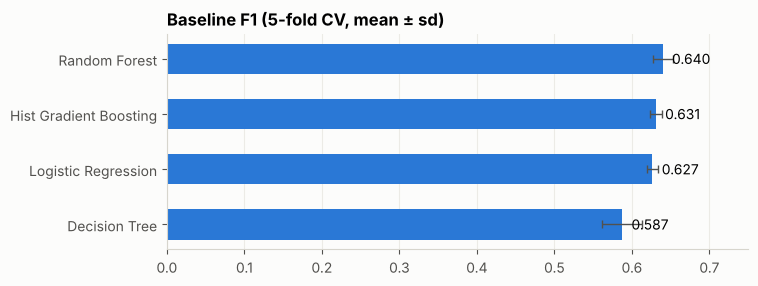

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
b = baseline.sort_values("f1")
ax.barh(b.index, b["f1"], xerr=b["f1_std"], color=BLUE, height=0.55, error_kw=dict(ecolor=MUTED, lw=1, capsize=3))
for i, v in enumerate(b["f1"]):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 0.75); ax.grid(axis="y", visible=False); ax.set_title("Baseline F1 (5-fold CV, mean ± sd)")
os.makedirs("../images", exist_ok=True)
fig.savefig("../images/10_baseline_models.png", dpi=130, bbox_inches="tight")

Random Forest, Gradient Boosting and Logistic Regression are within ~0.01 F1 of each other; the single Decision Tree (the original project's choice) is clearly behind and the least stable.
**Hist Gradient Boosting** is taken forward because it has a top-2 PR-AUC (0.73), the lowest-but-one variance across folds, trains ~3× faster than Random Forest, and has more room to improve with tuning.

## 4. Hyper-parameter tuning (RandomizedSearchCV, 40 candidates × 5 folds, optimising PR-AUC)

In [6]:
pipe = Pipeline([("prep", make_preprocessor()),
                 ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED))])
param_dist = {
    "model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
    "model__max_iter": [150, 250, 400, 600],
    "model__max_leaf_nodes": [7, 15, 31, 63],
    "model__min_samples_leaf": [20, 40, 80, 150],
    "model__l2_regularization": [0.0, 0.1, 0.5, 1.0, 3.0],
    "model__max_features": [0.5, 0.7, 1.0],
}
search = RandomizedSearchCV(pipe, param_dist, n_iter=40, scoring="average_precision", cv=cv,
                            n_jobs=-1, random_state=SEED, refit=True)
search.fit(X_train, y_train)
print("Best CV PR-AUC:", round(search.best_score_, 4))
search.best_params_

Best CV PR-AUC: 0.7422


{'model__min_samples_leaf': 150, 'model__max_leaf_nodes': 7, 'model__max_iter': 600, 'model__max_features': 0.7, 'model__learning_rate': 0.03, 'model__l2_regularization': 0.1}

## 5. Decision threshold
With `class_weight="balanced"` the default 0.5 threshold over-predicts buyers. The threshold that maximises F1 is chosen on **out-of-fold predictions of the training set**, so the test set stays untouched.

In [7]:
best_pipe = search.best_estimator_
oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_i = np.argmax(f1s[:-1])
THRESHOLD = float(round(thr[best_i], 3))
print(f"Threshold {THRESHOLD} → OOF F1 {f1s[best_i]:.3f} (precision {prec[best_i]:.3f}, recall {rec[best_i]:.3f})")
print(f"Default 0.5 → OOF F1 {f1_score(y_train, oof >= 0.5):.3f}")

Threshold 0.684 → OOF F1 0.670 (precision 0.627, recall 0.718)
Default 0.5 → OOF F1 0.631


## 6. Final evaluation on the hold-out test set

In [8]:
proba = best_pipe.predict_proba(X_test)[:, 1]
pred = (proba >= THRESHOLD).astype(int)
metrics = {
    "f1": f1_score(y_test, pred), "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
    "accuracy": accuracy_score(y_test, pred), "pr_auc": average_precision_score(y_test, proba),
    "roc_auc": roc_auc_score(y_test, proba),
}
print(classification_report(y_test, pred, target_names=["No purchase", "Purchase"], digits=3))
pd.Series(metrics).round(3)

              precision    recall  f1-score   support

 No purchase      0.938     0.915     0.926      2626
    Purchase      0.635     0.709     0.670       549

    accuracy                          0.879      3175
   macro avg      0.786     0.812     0.798      3175
weighted avg      0.885     0.879     0.882      3175



,0
f1,0.670
precision,0.635
recall,0.709
accuracy,0.879
pr_auc,0.750
roc_auc,0.906


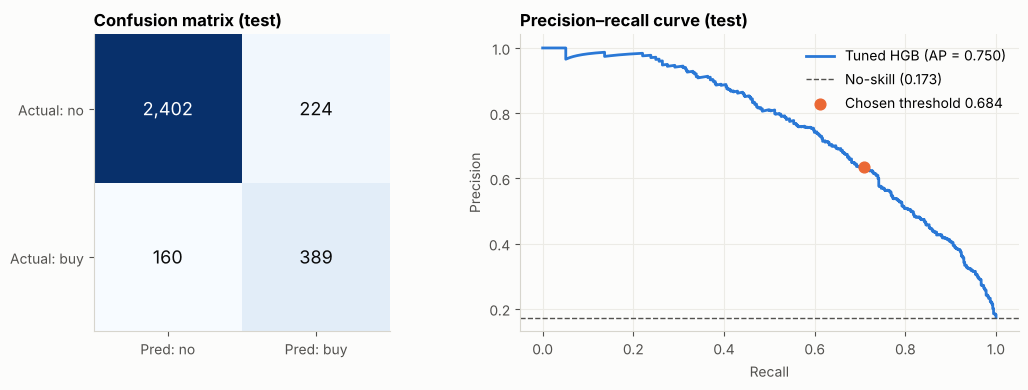

In [9]:
cm = confusion_matrix(y_test, pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else INK, fontsize=13)
ax.set_xticks([0, 1], ["Pred: no", "Pred: buy"]); ax.set_yticks([0, 1], ["Actual: no", "Actual: buy"])
ax.set_title("Confusion matrix (test)")
ax = axes[1]
p, r, _ = precision_recall_curve(y_test, proba)
ax.plot(r, p, color=BLUE, lw=2, label=f"Tuned HGB (AP = {metrics['pr_auc']:.3f})")
ax.axhline(y_test.mean(), color=MUTED, ls="--", lw=1, label=f"No-skill ({y_test.mean():.3f})")
ax.scatter([metrics["recall"]], [metrics["precision"]], color=ORANGE, s=60, zorder=3, label=f"Chosen threshold {THRESHOLD}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision–recall curve (test)")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig("../images/11_test_evaluation.png", dpi=130, bbox_inches="tight")

**Result:** on unseen sessions the tuned model reaches **F1 0.67, precision 0.63, recall 0.71 and PR-AUC 0.75** (no-skill PR-AUC = 0.17). Tuning + threshold moved F1 from 0.63 to 0.67. In plain words: of the sessions the model flags as buyers, about 2 in 3 really buy, and it finds 7 in 10 of all buyers.

## 7. What drives the prediction? (permutation importance on the test set)

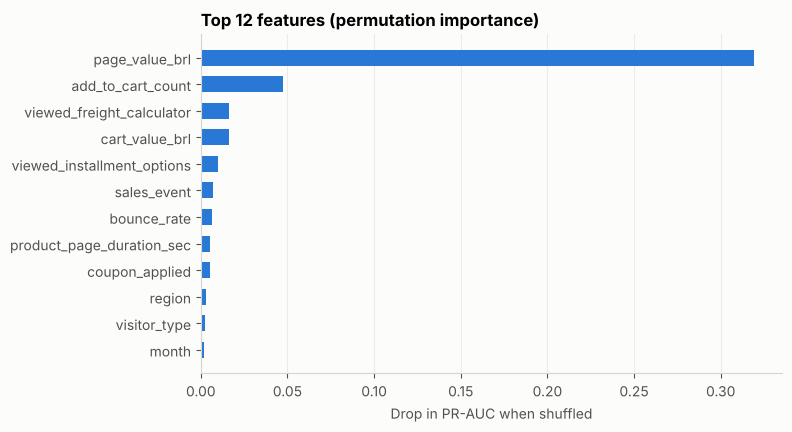

,0
page_value_brl,0.3194
add_to_cart_count,0.0476
viewed_freight_calculator,0.0162
cart_value_brl,0.0162
viewed_installment_options,0.0099
sales_event,0.0070
bounce_rate,0.0063
product_page_duration_sec,0.0055
coupon_applied,0.0055
region,0.0028


In [10]:
imp = permutation_importance(best_pipe, X_test, y_test, scoring="average_precision", n_repeats=10,
                             random_state=SEED, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.barh(imp_s.index, imp_s.values, color=BLUE, height=0.6)
ax.grid(axis="y", visible=False); ax.set_xlabel("Drop in PR-AUC when shuffled")
ax.set_title("Top 12 features (permutation importance)")
fig.savefig("../images/12_feature_importance.png", dpi=130, bbox_inches="tight")
imp_s.sort_values(ascending=False).round(4)

`page_value_brl` dominates, followed by cart activity and the two Brazil-specific signals — **freight calculator** and **installment options** — confirming the EDA.

## 8. Business view — cumulative gains
If the marketing team ranks live sessions by predicted probability and only acts on the top X%, how many of the real buyers do they reach?

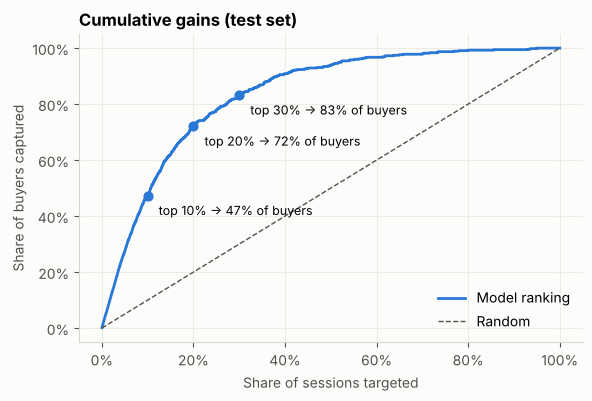

{'top_10pct': 0.47358834244080145, 'top_20pct': 0.7213114754098361, 'top_30pct': 0.8324225865209471}

In [11]:
order = np.argsort(-proba)
cum_buyers = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(share, cum_buyers, color=BLUE, lw=2, label="Model ranking")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="Random")
for k in [0.1, 0.2, 0.3]:
    v = cum_buyers[int(k * len(order)) - 1]
    ax.scatter([k], [v], color=BLUE, s=40, zorder=3)
    ax.annotate(f"top {k:.0%} → {v:.0%} of buyers", (k, v), xytext=(8, -14), textcoords="offset points", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of sessions targeted"); ax.set_ylabel("Share of buyers captured")
ax.set_title("Cumulative gains (test set)"); ax.legend(frameon=False, loc="lower right")
fig.savefig("../images/13_cumulative_gains.png", dpi=130, bbox_inches="tight")
gains = {f"top_{int(k*100)}pct": float(cum_buyers[int(k * len(order)) - 1]) for k in [0.1, 0.2, 0.3]}
gains

**Business takeaway:** acting on only the **top 20% of sessions reaches ~72% of buyers** (3.6× better than random). Practical uses for Casa & Estilo:
* **High score, no purchase yet** → show a free-shipping-threshold or *"parcele em 10x sem juros"* banner, or trigger a WhatsApp/e-mail cart reminder.
* **Low score** → don't spend a discount on them; show content / social proof instead.
* **Medium score** → best candidates for A/B tests of coupons.

## 9. Save the model
The whole pipeline (pre-processing + model) is saved, so the app only needs raw feature values.

In [12]:
os.makedirs("../models", exist_ok=True)
joblib.dump(best_pipe, "../models/purchase_intent_model.joblib", compress=3)
meta = {
    "model": "HistGradientBoostingClassifier (tuned)", "threshold": THRESHOLD,
    "features": {"numeric": NUM, "binary": BIN, "categorical": CAT},
    "categories": {c: sorted(df[c].unique().tolist()) for c in CAT},
    "test_metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    "cumulative_gains": {k: round(v, 4) for k, v in gains.items()},
    "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "sklearn_version": sklearn.__version__,
}
json.dump(meta, open("../models/model_metadata.json", "w"), indent=2)
print(json.dumps(meta["test_metrics"], indent=2))

{
  "f1": 0.6695,
  "precision": 0.6346,
  "recall": 0.7086,
  "accuracy": 0.8791,
  "pr_auc": 0.7504,
  "roc_auc": 0.9064
}
